# 23CSE301 Machine Learning Capstone — Clustering Track

**Dataset:** Gas Turbine CO and NOx Emission (2011–2015 combined)

**Objective:** Group turbine operating observations using the nine operating-condition features, then interpret CO and NOx emissions by cluster. Emissions and Year are not used as clustering inputs.

**Required algorithms:** K-Means and Agglomerative Hierarchical Clustering.

**Evaluation:** Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Index, elbow curve, linkage comparison, dendrogram, PCA visualisations and t-SNE.

**Reproducibility:** Random seed = 42. K-Means is fitted on all cleaned observations. Hierarchical clustering and its dendrogram use documented samples to control memory and computation.

## 1. Import libraries and set reproducibility

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (8, 5)
warnings.filterwarnings("ignore", category=FutureWarning)

## 2. Load the combined dataset

Place `gas_turbine_combined.csv` or `gas_turbine_combined_full_column_names.csv` in the same folder as this notebook. The code accepts either the abbreviated or descriptive column names.

In [2]:
DATA_CANDIDATES = ["gas_turbine_combined_full_column_names.csv", "gas_turbine_combined.csv"]
DATA_PATH = next((p for p in DATA_CANDIDATES if os.path.exists(p)), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Place gas_turbine_combined_full_column_names.csv or gas_turbine_combined.csv "
        "in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)

# Standardise column names internally so either supplied CSV works.
LONG_TO_SHORT = {
    "Ambient_Temperature": "AT", "Ambient_Pressure": "AP", "Ambient_Humidity": "AH",
    "Air_Filter_Differential_Pressure": "AFDP", "Gas_Turbine_Exhaust_Pressure": "GTEP",
    "Turbine_Inlet_Temperature": "TIT", "Turbine_After_Temperature": "TAT",
    "Turbine_Energy_Yield": "TEY", "Compressor_Discharge_Pressure": "CDP",
    "Carbon_Monoxide_Emission": "CO", "Nitrogen_Oxides_Emission": "NOX",
}
df = df.rename(columns=LONG_TO_SHORT)

print("Loaded file:", DATA_PATH)
print("Raw dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Loaded file: gas_turbine_combined_full_column_names.csv
Raw dataset shape: (36733, 12)
Columns: ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP', 'CO', 'NOX', 'Year']


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,Year
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011


## 3. Dataset audit

Inspect data types, missing values, duplicate rows and summary statistics before preprocessing.

In [3]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("Missing values by column:")
display(df.isna().sum().to_frame("missing_values"))

print("Exact duplicate rows:", df.duplicated().sum())

print("Summary statistics:")
display(df.describe().T.round(3))

Data types:


,dtype
AT,float64
AP,float64
AH,float64
AFDP,float64
GTEP,float64
TIT,float64
TAT,float64
TEY,float64
CDP,float64
CO,float64


Missing values by column:


,missing_values
AT,0
AP,0
AH,0
AFDP,0
GTEP,0
TIT,0
TAT,0
TEY,0
CDP,0
CO,0


Exact duplicate rows: 7
Summary statistics:


,count,mean,std,min,25%,50%,75%,max
AT,36733.0,17.713,7.447,-6.235,11.781,17.801,23.665,37.103
AP,36733.0,1013.070,6.463,985.850,1008.800,1012.600,1017.000,1036.600
AH,36733.0,77.867,14.461,24.085,68.188,80.470,89.376,100.200
AFDP,36733.0,3.926,0.774,2.087,3.356,3.938,4.377,7.611
GTEP,36733.0,25.564,4.196,17.698,23.129,25.104,29.061,40.716
TIT,36733.0,1081.428,17.536,1000.800,1071.800,1085.900,1097.000,1100.900
TAT,36733.0,546.159,6.842,511.040,544.720,549.880,550.040,550.610
TEY,36733.0,133.506,15.619,100.020,124.450,133.730,144.080,179.500
CDP,36733.0,12.061,1.089,9.852,11.435,11.965,12.855,15.159
CO,36733.0,2.372,2.263,0.000,1.182,1.714,2.843,44.103


### Data cleaning

Remove exact duplicate records. Missing/non-finite values in the operating features are handled before clustering. Keep `Year` and emission columns for later interpretation, but do not use them as clustering inputs.

In [4]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Rows before removing exact duplicates:", rows_before)
print("Rows after removing exact duplicates:", len(df))
print("Exact duplicates removed:", rows_before - len(df))

# Replace infinite values with NaN, then remove rows missing required numeric inputs.
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)
required_for_analysis = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP", "CO", "NOX"]
missing_required = [c for c in required_for_analysis if c not in df.columns]
if missing_required:
    raise ValueError(f"Required columns are missing: {missing_required}")
rows_before_missing = len(df)
df = df.dropna(subset=required_for_analysis).reset_index(drop=True)
print("Rows removed due to missing/non-finite required values:", rows_before_missing - len(df))
print("Cleaned dataset shape:", df.shape)
print("Missing values remaining in required columns:", int(df[required_for_analysis].isna().sum().sum()))

Rows before removing exact duplicates: 36733
Rows after removing exact duplicates: 36726
Exact duplicates removed: 7
Rows removed due to missing/non-finite required values: 0
Cleaned dataset shape: (36726, 12)
Missing values remaining in required columns: 0


## 4. Select features for clustering

Use all nine turbine operating-condition features. Keep CO and NOx out of model fitting so they can be compared across the resulting clusters afterward.

In [5]:
operating_features = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]
emission_features = ["CO", "NOX"]

missing_columns = [c for c in operating_features + emission_features if c not in df.columns]
if missing_columns:
    raise ValueError(f"Expected columns not found: {missing_columns}")

X = df[operating_features].astype(float).copy()
print("Number of clustering features:", X.shape[1])
print("Features used:", operating_features)
print("Rows used for K-Means:", len(X))
display(X.head())

Number of clustering features: 9
Features used: ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']
Rows used for K-Means: 36726


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910


### Quick exploratory visualisations
These plots help inspect distributions and relationships before clustering.

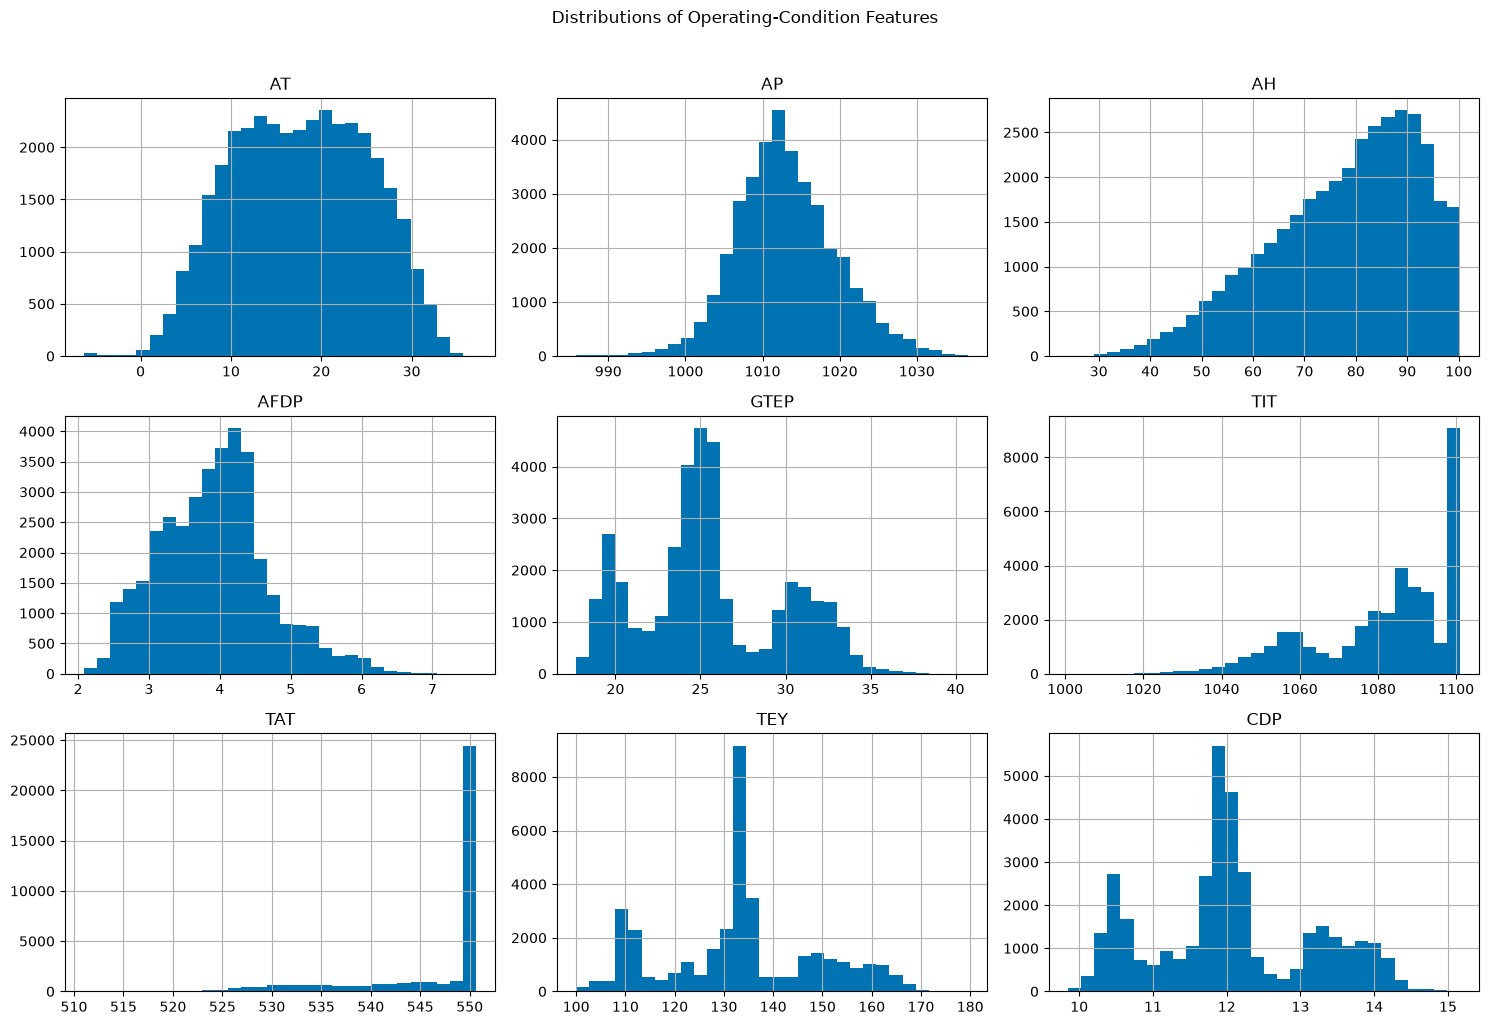

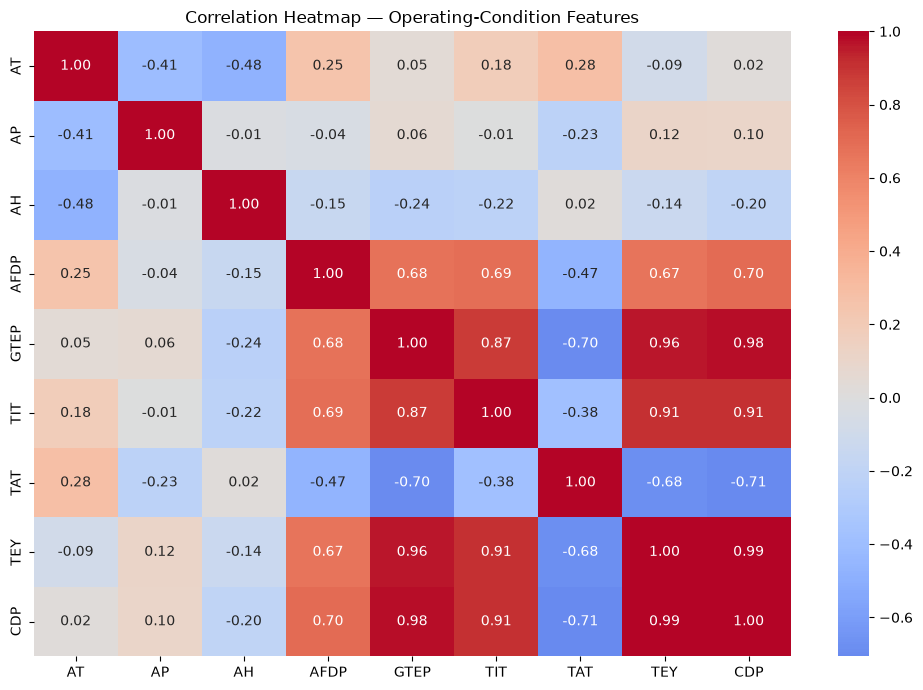

In [6]:
X.hist(figsize=(15, 10), bins=30)
plt.suptitle("Distributions of Operating-Condition Features", y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap — Operating-Condition Features")
plt.tight_layout()
plt.show()

## 5. Scale the numerical features

K-Means and hierarchical clustering are distance-based, so feature scaling is necessary. Use `StandardScaler` as the main baseline. The notebook retains only one full scaled matrix to reduce memory usage.

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled matrix shape:", X_scaled.shape)
print("Data type:", X_scaled.dtype)
print("Approximate feature means:", np.round(X_scaled.mean(axis=0), 3))
print("Approximate feature standard deviations:", np.round(X_scaled.std(axis=0), 3))

Scaled matrix shape: (36726, 9)
Data type: float64
Approximate feature means: [ 0.  0. -0.  0. -0.  0. -0.  0. -0.]
Approximate feature standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 6. K-Means — Elbow curve

Fit K-Means for a range of `k` values on the full cleaned dataset. Inertia decreases as `k` increases; use the elbow as one piece of evidence rather than an automatic decision rule.

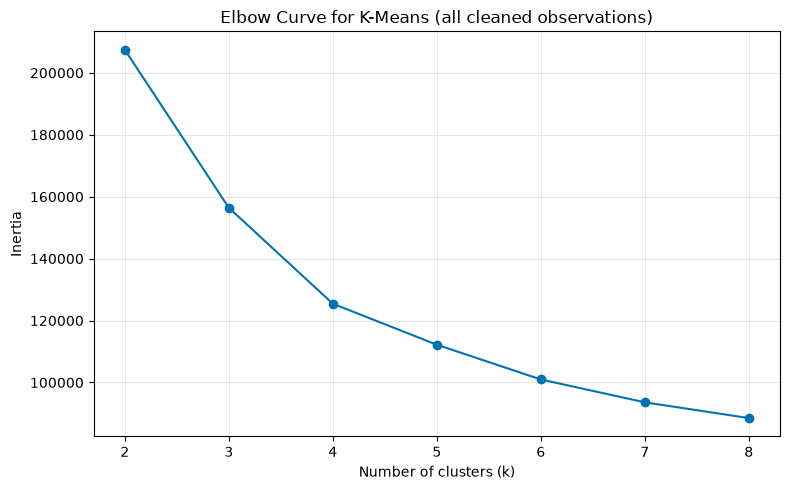

In [8]:
k_values = range(2, 9)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Curve for K-Means (all cleaned observations)")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### K-Means — compare candidate values of k

For each candidate, fit K-Means on all cleaned rows. Compute Silhouette on the same fixed evaluation subset to keep the calculation manageable; compute Davies–Bouldin and Calinski–Harabasz on all rows. The sample size is shown explicitly. Consider all metrics, the elbow curve, cluster sizes and interpretability when choosing `k`.

,k,Inertia (all rows),Silhouette (sample n=5000),Davies-Bouldin (all rows),Calinski-Harabasz (all rows),Smallest cluster (all rows),Largest cluster (all rows)
0,2,207448.7025,0.3723,1.0867,21789.4129,9622,27104
1,3,156429.1718,0.3066,1.2180,20436.2625,8696,19007
2,4,125444.4254,0.2953,1.1797,20012.3651,5949,13118
3,5,112200.6209,0.2622,1.2460,17864.0553,5782,9049
4,6,100979.9688,0.2561,1.2419,16694.8706,4570,7561
5,7,93598.8610,0.2466,1.3501,15491.7197,2786,7270
6,8,88507.3133,0.2326,1.4005,14343.8563,2763,7166


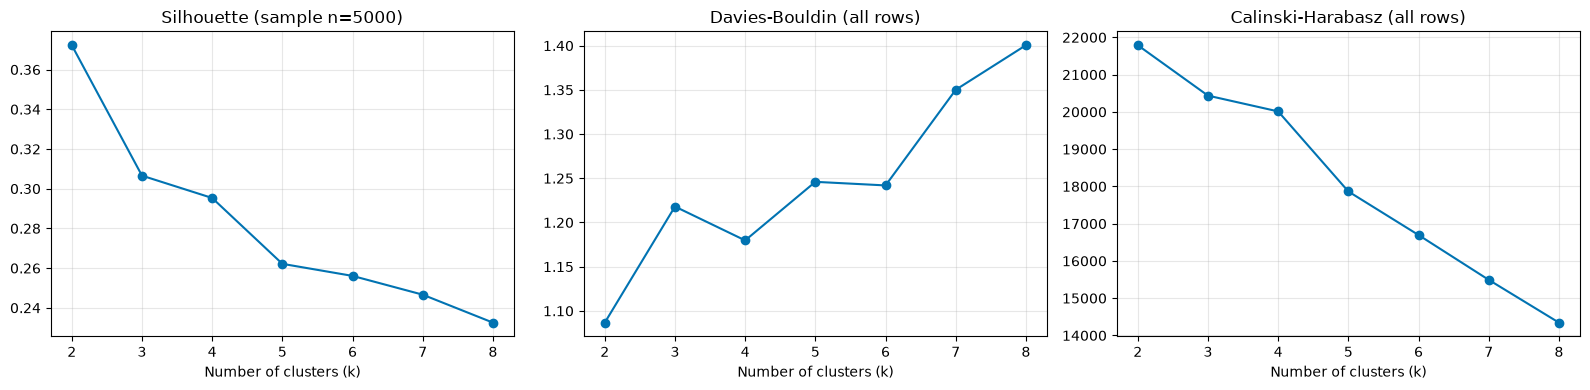

In [9]:
# Fixed subset used only to estimate Silhouette for candidate K values.
SILHOUETTE_SAMPLE_SIZE = min(5000, len(X_scaled))
eval_rng = np.random.RandomState(RANDOM_STATE)
eval_positions = np.sort(eval_rng.choice(len(X_scaled), size=SILHOUETTE_SAMPLE_SIZE, replace=False))

k_rows = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)  # fit on all cleaned rows
    subset_labels = labels[eval_positions]
    subset_X = X_scaled[eval_positions]
    sizes = np.bincount(labels, minlength=k)
    k_rows.append({
        "k": k,
        "Inertia (all rows)": model.inertia_,
        f"Silhouette (sample n={SILHOUETTE_SAMPLE_SIZE})": silhouette_score(subset_X, subset_labels),
        "Davies-Bouldin (all rows)": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz (all rows)": calinski_harabasz_score(X_scaled, labels),
        "Smallest cluster (all rows)": int(sizes.min()),
        "Largest cluster (all rows)": int(sizes.max()),
    })
k_table = pd.DataFrame(k_rows)
display(k_table.round(4))

sil_col = f"Silhouette (sample n={SILHOUETTE_SAMPLE_SIZE})"
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, [sil_col, "Davies-Bouldin (all rows)", "Calinski-Harabasz (all rows)"]):
    ax.plot(k_table["k"], k_table[col], marker="o")
    ax.set_title(col)
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(list(k_values))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Fit the selected K-Means model

Set `KMEANS_K` after reviewing the elbow curve and comparison table. The default is `3` as a transparent starting candidate, not a claim that it is universally optimal. The final K-Means model is fitted on every cleaned observation.

In [10]:
# Review the elbow curve, metric table, cluster sizes and interpretability before finalising k.
# Default candidate is 3; change this value only when your evidence supports another choice.
KMEANS_K = 3
print("K-Means cluster count selected for analysis:", KMEANS_K)

kmeans = KMeans(n_clusters=KMEANS_K, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)  # all cleaned observations

df["KMeans_Cluster"] = kmeans_labels
print("K-Means cluster counts on the full cleaned dataset:")
display(df["KMeans_Cluster"].value_counts().sort_index().to_frame("instances"))

K-Means cluster count selected for analysis: 3
K-Means cluster counts on the full cleaned dataset:


,instances
KMeans_Cluster,
0,19007
1,9023
2,8696


## 7. Agglomerative Hierarchical Clustering — compare linkage strategies

Agglomerative clustering can require substantially more memory and computation than K-Means. Compare Ward, complete and average linkage on the same fixed sample, and report that sample size with the results.

In [11]:
# One reproducible sample is used for all hierarchical linkage and same-sample model comparisons.
HIERARCHICAL_SAMPLE_SIZE = min(2000, len(df))
sample_positions = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(df), size=HIERARCHICAL_SAMPLE_SIZE, replace=False))
sample_df = df.iloc[sample_positions].copy()
X_hier = X_scaled[sample_positions]

print("Rows used for hierarchical clustering:", len(sample_df))
print("Rows used to fit final K-Means:", len(df))

Rows used for hierarchical clustering: 2000
Rows used to fit final K-Means: 36726


In [12]:
linkage_results = []
hier_labels = {}

for linkage_name in ["ward", "complete", "average"]:
    agg = AgglomerativeClustering(n_clusters=KMEANS_K, linkage=linkage_name)
    labels = agg.fit_predict(X_hier)
    hier_labels[linkage_name] = labels
    sizes = np.bincount(labels)
    linkage_results.append({
        "Linkage": linkage_name,
        "Smallest cluster": int(sizes.min()),
        "Largest cluster": int(sizes.max()),
        "Silhouette Score": silhouette_score(X_hier, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_hier, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_hier, labels)
    })

linkage_results_df = pd.DataFrame(linkage_results).sort_values(
    "Silhouette Score", ascending=False
).reset_index(drop=True)

# A linkage that leaves a tiny cluster (under 1% of the sample) is not a meaningful result
MIN_CLUSTER_SIZE = int(0.01 * len(X_hier))
linkage_results_df["Valid (no tiny cluster)"] = linkage_results_df["Smallest cluster"] >= MIN_CLUSTER_SIZE
display(linkage_results_df.round(4))

valid_links = linkage_results_df[linkage_results_df["Valid (no tiny cluster)"]]
AGG_LINKAGE = valid_links.iloc[0]["Linkage"] if len(valid_links) else "ward"
print(f"Selected linkage: {AGG_LINKAGE} (highest Silhouette among linkages with no tiny cluster; "
      f"minimum cluster size = {MIN_CLUSTER_SIZE} rows)")
rejected = linkage_results_df[~linkage_results_df["Valid (no tiny cluster)"]]["Linkage"].tolist()
if rejected:
    print("Rejected because of a tiny cluster (their metric values are not meaningful):", rejected)

,Linkage,Smallest cluster,Largest cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Valid (no tiny cluster)
0,average,1,1997,0.3391,0.4455,8.1440,False
1,ward,359,1234,0.2845,1.1750,933.6118,True
2,complete,251,1481,0.2675,1.1151,764.6248,True


Selected linkage: ward (highest Silhouette among linkages with no tiny cluster; minimum cluster size = 20 rows)
Rejected because of a tiny cluster (their metric values are not meaningful): ['average']


### How the linkage is selected

Compare all linkage strategies on the same sample. Inspect all three metrics and cluster sizes. A method that creates singleton or very small clusters should be interpreted cautiously; do not select a method based only on one score.

### Dendrogram

The dendrogram uses a smaller fixed sample because a dendrogram of all 36,000+ records would be expensive and difficult to read. This is a visual diagnostic, not a full-dataset hierarchical fit.

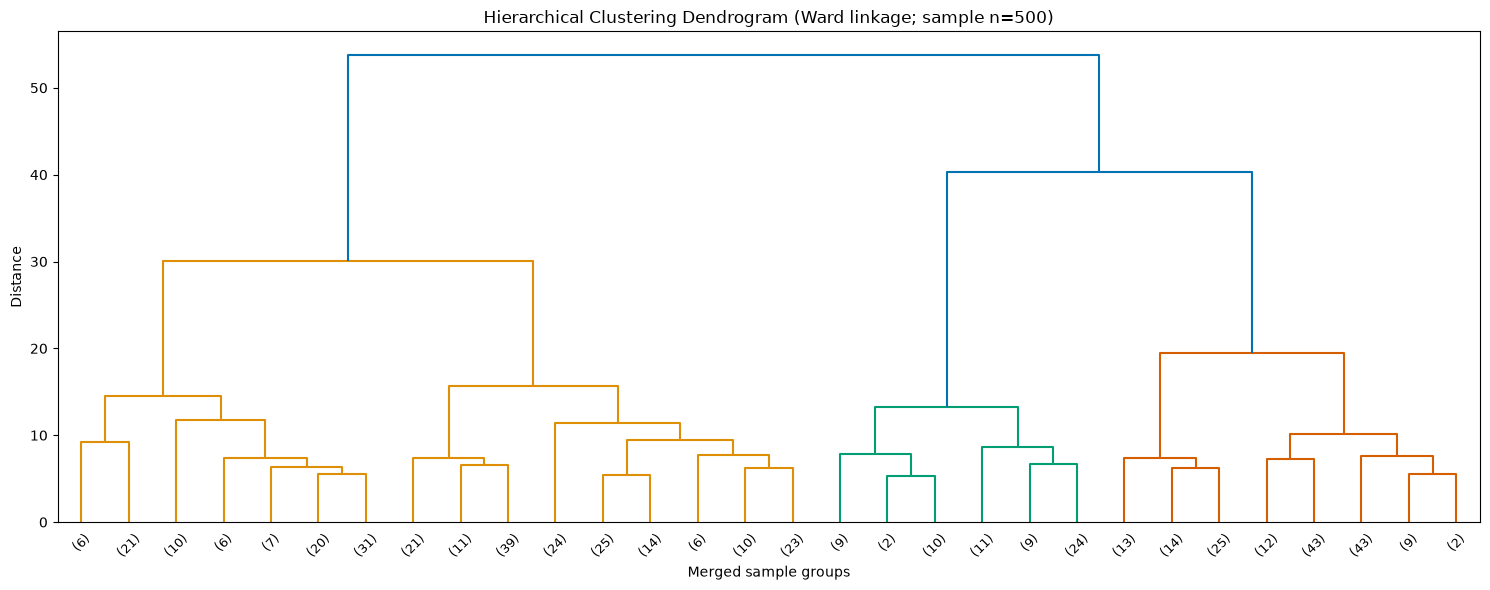

In [13]:
DENDROGRAM_SAMPLE_SIZE = min(500, len(sample_df))
dendro_local_positions = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(sample_df), size=DENDROGRAM_SAMPLE_SIZE, replace=False))
X_dendro = X_hier[dendro_local_positions]

Z = linkage(X_dendro, method="ward")
plt.figure(figsize=(15, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=45, leaf_font_size=9)
plt.title(f"Hierarchical Clustering Dendrogram (Ward linkage; sample n={len(X_dendro)})")
plt.xlabel("Merged sample groups")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

## 8. Fit final Agglomerative model and compare required metrics

For a fair algorithm comparison, evaluate K-Means and the selected Agglomerative linkage on the same fixed hierarchical sample. The separate full-dataset K-Means metrics are reported in Section 12.

In [14]:
print("Agglomerative linkage used:", AGG_LINKAGE)

X_eval = X_hier
# Both algorithms are refitted/evaluated on the exact same sample for a fair comparison.
kmeans_eval = KMeans(n_clusters=KMEANS_K, random_state=RANDOM_STATE, n_init=10)
kmeans_eval_labels = kmeans_eval.fit_predict(X_eval)
agg_final = AgglomerativeClustering(n_clusters=KMEANS_K, linkage=AGG_LINKAGE)
agg_labels = agg_final.fit_predict(X_eval)

evaluation_rows = []
for model_name, labels in [("K-Means", kmeans_eval_labels), (f"Agglomerative ({AGG_LINKAGE})", agg_labels)]:
    evaluation_rows.append({
        "Algorithm": model_name,
        "Rows evaluated": len(X_eval),
        "Number of clusters": len(np.unique(labels)),
        "Smallest cluster": int(np.bincount(labels).min()),
        "Silhouette Score": silhouette_score(X_eval, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_eval, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_eval, labels)
    })
evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df.round(4))

Agglomerative linkage used: ward


,Algorithm,Rows evaluated,Number of clusters,Smallest cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,2000,3,343,0.2863,1.1835,1101.9090
1,Agglomerative (ward),2000,3,359,0.2845,1.1750,933.6118


## 9. PCA visualisation — both algorithms
PCA reduces the scaled feature matrix to two dimensions for visualisation. The clustering models are fitted on the original scaled features, not on these two plotted components.

Explained variance ratio: [0.5414 0.2059]
Total variance explained by 2 components: 0.7473


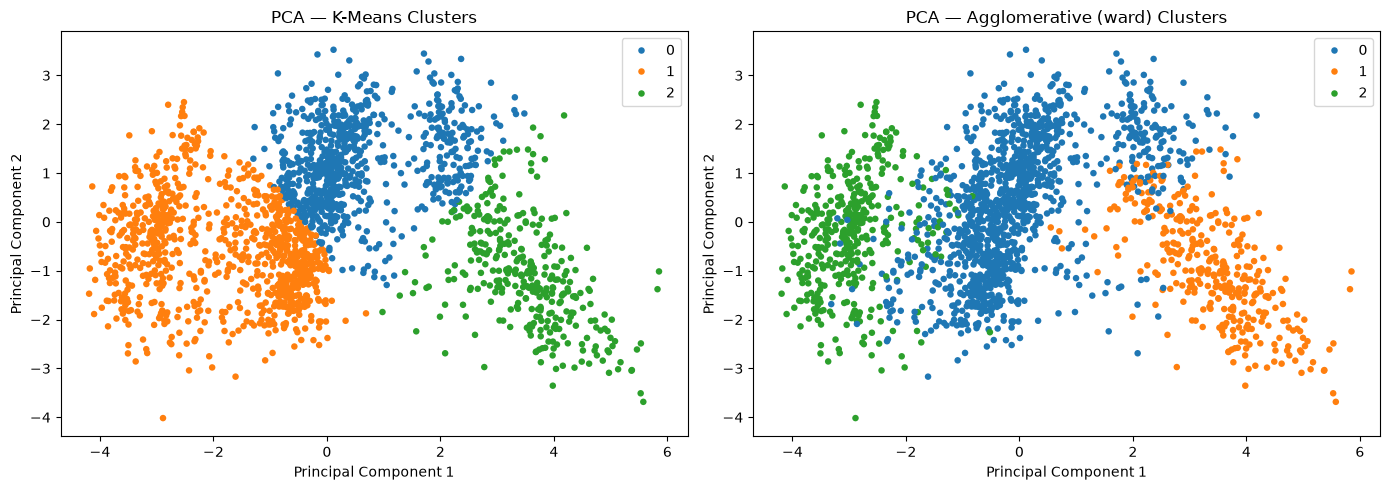

In [15]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_eval)
print("Explained variance ratio:", np.round(pca.explained_variance_ratio_, 4))
print("Total variance explained by 2 components:",
      round(pca.explained_variance_ratio_.sum(), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_eval_labels,
                palette="tab10", s=22, linewidth=0, ax=axes[0], legend="brief")
axes[0].set_title("PCA — K-Means Clusters")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=agg_labels,
                palette="tab10", s=22, linewidth=0, ax=axes[1], legend="brief")
axes[1].set_title(f"PCA — Agglomerative ({AGG_LINKAGE}) Clusters")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

## 10. t-SNE visualisation

t-SNE is computationally intensive and is used here on a fixed sample. It is a visualisation of local structure, not a clustering algorithm or a substitute for the three required metrics.

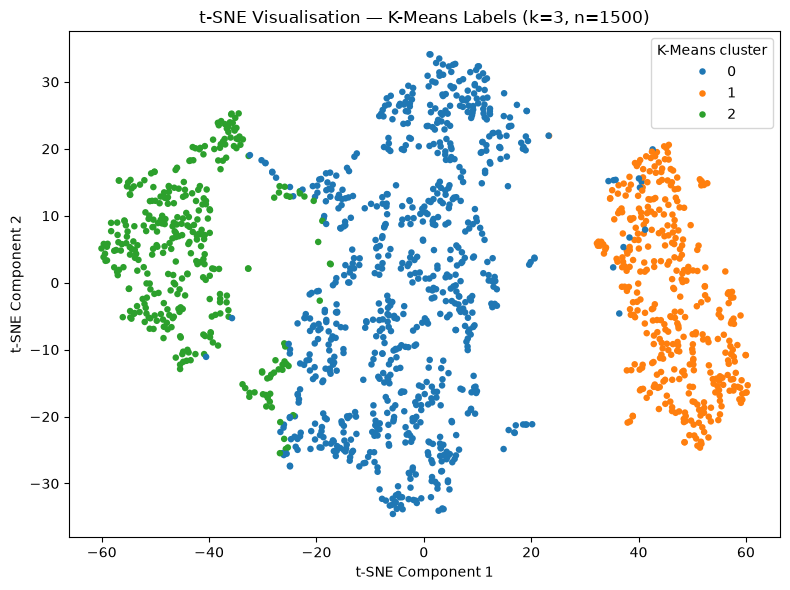

In [16]:
TSNE_SAMPLE_SIZE = min(1500, len(df))
tsne_positions = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(df), size=TSNE_SAMPLE_SIZE, replace=False))
X_tsne_input = X_scaled[tsne_positions]
tsne_labels = kmeans_labels[tsne_positions]

tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=min(30, (TSNE_SAMPLE_SIZE - 1) / 3),
            init="pca", learning_rate="auto")
X_tsne = tsne.fit_transform(X_tsne_input)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=tsne_labels,
                palette="tab10", s=22, linewidth=0)
plt.title(f"t-SNE Visualisation — K-Means Labels (k={KMEANS_K}, n={TSNE_SAMPLE_SIZE})")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.legend(title="K-Means cluster")
plt.tight_layout()
plt.show()

## 11. Interpret clusters using CO and NOx after clustering

The emissions were excluded from the clustering inputs. Compare their distributions across K-Means clusters to help interpret the operating groups; observed associations do not establish causation.

Mean of each feature per cluster (original units):


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,Number of rows
KMeans_Cluster,,,,,,,,,,,,
0,18.451,1012.712,77.674,3.899,25.127,1085.119,549.804,133.056,11.980,1.760,65.393,19007
1,17.517,1013.924,74.171,4.706,31.560,1099.660,536.323,154.824,13.609,1.278,62.271,9023
2,16.297,1012.973,82.113,3.172,20.295,1054.440,548.393,112.371,10.629,4.848,68.223,8696


Median CO and NOX per cluster:


,CO,NOX
KMeans_Cluster,,
0,1.607,64.376
1,1.178,61.491
2,4.271,64.227


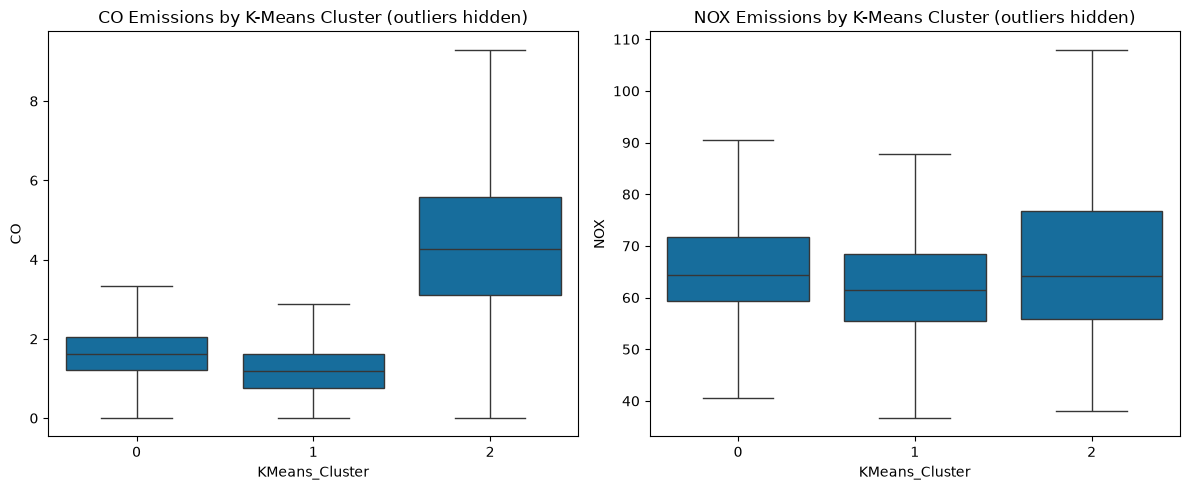

In [17]:
cluster_profile = df.groupby("KMeans_Cluster")[operating_features + emission_features].mean()
cluster_sizes = df["KMeans_Cluster"].value_counts().sort_index().rename("Number of rows")
cluster_profile = cluster_profile.join(cluster_sizes)
print("Mean of each feature per cluster (original units):")
display(cluster_profile.round(3))

# CO is skewed (a few very large values), so medians are shown as well as means
print("Median CO and NOX per cluster:")
display(df.groupby("KMeans_Cluster")[emission_features].median().round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x="KMeans_Cluster", y="CO", ax=axes[0], showfliers=False)
axes[0].set_title("CO Emissions by K-Means Cluster (outliers hidden)")
sns.boxplot(data=df, x="KMeans_Cluster", y="NOX", ax=axes[1], showfliers=False)
axes[1].set_title("NOX Emissions by K-Means Cluster (outliers hidden)")
plt.tight_layout()
plt.show()

## 12. Final results summary, rubric check and conclusion

The final tables distinguish (1) both algorithms evaluated on the same hierarchical sample and (2) K-Means metrics calculated on all cleaned rows. Silhouette is sampled for the full-data K-Means model to reduce computational cost; the sample size is stated.

In [18]:
print(f"FINAL ALGORITHM COMPARISON — SAME {len(X_eval):,}-ROW SAMPLE")
display(evaluation_df.round(4))

print(f"LINKAGE STRATEGY COMPARISON — SAME {len(X_hier):,}-ROW SAMPLE")
display(linkage_results_df.round(4))

# Full-dataset K-Means metrics: Silhouette is estimated on a fixed sample, other two metrics use all rows.
full_km_metrics = {
    "Algorithm": f"K-Means (k={KMEANS_K}) — full cleaned dataset",
    "Rows fitted": len(df),
    "Silhouette evaluation rows": SILHOUETTE_SAMPLE_SIZE,
    "Silhouette Score (sample estimate)": silhouette_score(X_scaled[eval_positions], kmeans_labels[eval_positions]),
    "Davies-Bouldin Index (all rows)": davies_bouldin_score(X_scaled, kmeans_labels),
    "Calinski-Harabasz Index (all rows)": calinski_harabasz_score(X_scaled, kmeans_labels),
}
print("K-MEANS METRICS — FITTED ON ALL CLEANED OBSERVATIONS")
display(pd.DataFrame([full_km_metrics]).round(4))

print("K-Means cluster sizes (full cleaned dataset)")
display(df["KMeans_Cluster"].value_counts().sort_index().to_frame("instances"))

FINAL ALGORITHM COMPARISON — SAME 2,000-ROW SAMPLE


,Algorithm,Rows evaluated,Number of clusters,Smallest cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,2000,3,343,0.2863,1.1835,1101.9090
1,Agglomerative (ward),2000,3,359,0.2845,1.1750,933.6118


LINKAGE STRATEGY COMPARISON — SAME 2,000-ROW SAMPLE


,Linkage,Smallest cluster,Largest cluster,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Valid (no tiny cluster)
0,average,1,1997,0.3391,0.4455,8.1440,False
1,ward,359,1234,0.2845,1.1750,933.6118,True
2,complete,251,1481,0.2675,1.1151,764.6248,True


K-MEANS METRICS — FITTED ON ALL CLEANED OBSERVATIONS


,Algorithm,Rows fitted,Silhouette evaluation rows,Silhouette Score (sample estimate),Davies-Bouldin Index (all rows),Calinski-Harabasz Index (all rows)
0,K-Means (k=3) — full cleaned dataset,36726,5000,0.3066,1.218,20436.2625


K-Means cluster sizes (full cleaned dataset)


,instances
KMeans_Cluster,
0,19007
1,9023
2,8696


In [19]:
km_row = evaluation_df.iloc[0]
ag_row = evaluation_df.iloc[1]
def status(ok):
    return "Included" if ok else "Needs attention"

rubric_matrix = pd.DataFrame([
    ["B1", "K-Means fitted and labels obtained", f"k={KMEANS_K}; {len(kmeans_labels):,} labels on all cleaned rows", status(len(kmeans_labels) == len(df))],
    ["B1", "Agglomerative fitted and labels obtained", f"{AGG_LINKAGE}; k={KMEANS_K}; {len(agg_labels):,} sample labels", status(len(agg_labels) == len(X_eval))],
    ["B2", "All three metrics for both algorithms", "Same-sample comparison table in Section 8", status(all(c in evaluation_df.columns for c in ["Silhouette Score", "Davies-Bouldin Index", "Calinski-Harabasz Index"]))],
    ["B2", "K-Means elbow curve", "Section 6", "Included"],
    ["B2", "Hierarchical linkage comparison and dendrogram", "Section 7", "Included"],
    ["B3", "PCA 2-D cluster plots for both algorithms", "Section 9", "Included"],
    ["B3", "t-SNE visualisation for at least one algorithm", "Section 10", "Included"],
    ["Method", "CO/NOX/Year excluded from clustering inputs", "Nine operating features only", status(not (set(operating_features) & set(emission_features + ["Year"])))],
], columns=["Rubric", "Requirement", "Evidence", "Status"])
print("CLUSTERING RUBRIC CHECK")
display(rubric_matrix)

CLUSTERING RUBRIC CHECK


,Rubric,Requirement,Evidence,Status
0,B1,K-Means fitted and labels obtained,"k=3; 36,726 labels on all cleaned rows",Included
1,B1,Agglomerative fitted and labels obtained,"ward; k=3; 2,000 sample labels",Included
2,B2,All three metrics for both algorithms,Same-sample comparison table in Section 8,Included
3,B2,K-Means elbow curve,Section 6,Included
4,B2,Hierarchical linkage comparison and dendrogram,Section 7,Included
5,B3,PCA 2-D cluster plots for both algorithms,Section 9,Included
6,B3,t-SNE visualisation for at least one algorithm,Section 10,Included
7,Method,CO/NOX/Year excluded from clustering inputs,Nine operating features only,Included


In [20]:
def describe_silhouette(s):
    if s > 0.70: return "strong separation in this representation"
    if s > 0.50: return "reasonably separated groups in this representation"
    if s > 0.25: return "some cluster structure, with potential overlap"
    return "limited separation in this representation"

by_load = df.groupby("KMeans_Cluster")["TEY"].mean().sort_values()
med = df.groupby("KMeans_Cluster")[emission_features].median()
low, high = by_load.index[0], by_load.index[-1]

better = sum([
    km_row["Silhouette Score"] > ag_row["Silhouette Score"],
    km_row["Davies-Bouldin Index"] < ag_row["Davies-Bouldin Index"],
    km_row["Calinski-Harabasz Index"] > ag_row["Calinski-Harabasz Index"],
])

print("CONCLUSION SUMMARY (based on the outputs above)\n")
print(f"1) K-Means uses all {len(df):,} cleaned observations and all nine operating-condition features; selected k = {KMEANS_K}.")
print(f"2) On the same {len(X_eval):,}-row evaluation sample:")
print(f"   K-Means: Silhouette {km_row['Silhouette Score']:.4f} | Davies-Bouldin {km_row['Davies-Bouldin Index']:.4f} | Calinski-Harabasz {km_row['Calinski-Harabasz Index']:,.2f}")
print(f"   Agglomerative ({AGG_LINKAGE}): Silhouette {ag_row['Silhouette Score']:.4f} | Davies-Bouldin {ag_row['Davies-Bouldin Index']:.4f} | Calinski-Harabasz {ag_row['Calinski-Harabasz Index']:,.2f}")
print(f"   K-Means is better on {better} of the three metrics in this sample; interpret the metrics together with cluster sizes and profiles.")
print(f"3) Silhouette interpretation: {describe_silhouette(km_row['Silhouette Score'])}.")
print(f"4) PCA's first two components explain {pca.explained_variance_ratio_.sum():.1%} of the variance; the 2-D plot is a simplified view.")
print(f"5) Cluster {low} has the lowest mean turbine energy yield ({by_load[low]:.2f}); cluster {high} has the highest ({by_load[high]:.2f}).")
print(f"   Median CO: cluster {low}={med.loc[low, 'CO']:.3f}, cluster {high}={med.loc[high, 'CO']:.3f}; median NOX: cluster {low}={med.loc[low, 'NOX']:.3f}, cluster {high}={med.loc[high, 'NOX']:.3f}.")
print("6) Limitations: hierarchical clustering, dendrogram and t-SNE use documented samples; these clusters describe similarity, not causation.")

CONCLUSION SUMMARY (based on the outputs above)

1) K-Means uses all 36,726 cleaned observations and all nine operating-condition features; selected k = 3.
2) On the same 2,000-row evaluation sample:
   K-Means: Silhouette 0.2863 | Davies-Bouldin 1.1835 | Calinski-Harabasz 1,101.91
   Agglomerative (ward): Silhouette 0.2845 | Davies-Bouldin 1.1750 | Calinski-Harabasz 933.61
   K-Means is better on 2 of the three metrics in this sample; interpret the metrics together with cluster sizes and profiles.
3) Silhouette interpretation: some cluster structure, with potential overlap.
4) PCA's first two components explain 74.7% of the variance; the 2-D plot is a simplified view.
5) Cluster 2 has the lowest mean turbine energy yield (112.37); cluster 1 has the highest (154.82).
   Median CO: cluster 2=4.271, cluster 1=1.178; median NOX: cluster 2=64.227, cluster 1=61.491.
6) Limitations: hierarchical clustering, dendrogram and t-SNE use documented samples; these clusters describe similarity, not 

### Notes for the write-up

- State the actual cleaned row count and all nine input features.
- Explain that CO and NOx were reserved for post-clustering interpretation.
- State clearly that K-Means was fitted on all cleaned observations, while hierarchical clustering and its dendrogram use samples for computational practicality.
- Report metric values exactly as produced by the executed notebook. Do not claim a target score was achieved unless the displayed output supports it.
- Discuss limitations: distance-based results depend on scaling and feature representation; cluster associations with emissions are not causal.